# 고속도로 구간별 정체 예측 LSTM 모델
**예측 대상:** VOL(교통량), SPD(속도), OCC(점유율)  
**모델:** LSTM (Multi-output)

## 0. 라이브러리 설치 및 임포트

In [1]:
# 필요 패키지 설치 (최초 1회)
# !pip install torch scikit-learn pandas numpy matplotlib seaborn tqdm

In [2]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

# 재현성 고정
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 디바이스: {DEVICE}')

print(torch.cuda.is_available())        # True 나와야 함
print(torch.cuda.get_device_name(0))    # RTX 5070 나와야 함
print(torch.cuda.memory_allocated())    # 현재 사용 중인 VRAM

사용 디바이스: cuda
True
NVIDIA GeForce RTX 5070
0


## 1. 데이터 로드

In [3]:
# ⚙️ 설정 - 데이터 폴더 경로를 맞게 수정하세요
DATA_DIR = "D:\\엔지니어링 공모전\\data_set\\program01_data_finish"  # CSV 파일들이 있는 폴더

csv_files = glob.glob(os.path.join(DATA_DIR, '*.csv'))
print(f'발견된 CSV 파일 수: {len(csv_files)}')

df_list = []
for f in tqdm(csv_files, desc='CSV 로딩'):
    tmp = pd.read_csv(f, encoding='utf-8-sig')
    df_list.append(tmp)

df = pd.concat(df_list, ignore_index=True)
print(f'전체 데이터 shape: {df.shape}')
df.head(3)

발견된 CSV 파일 수: 160


CSV 로딩: 100%|██████████| 160/160 [00:22<00:00,  7.12it/s]


전체 데이터 shape: (16491792, 25)


,DATE_CD,ROUTE_ID,ROUTE_NAME,LINK_ID,ROAD_NAME,HH5M_CD,VOL,SPD,OCC,day_sin,...,weekday,month,hour,acc_weekday,acc_month,acc_hour,강수량(mm),적설(cm),시정(10m),is_holiday
0,20250101,LBL3000010,북부간선로,LBL2000020,묵동IC←신내IC,0.0,87.0,86.10,3.60,0.017213,...,2.0,1.0,0.0,0.533333,0.695652,0.15,0.0,0.0,3546,1
1,20250101,LBL3000010,북부간선로,LBL2000020,묵동IC←신내IC,5.0,82.0,92.24,3.04,0.017213,...,2.0,1.0,0.0,0.533333,0.695652,0.15,0.0,0.0,3546,1
2,20250101,LBL3000010,북부간선로,LBL2000020,묵동IC←신내IC,10.0,90.0,88.76,3.69,0.017213,...,2.0,1.0,0.0,0.533333,0.695652,0.15,0.0,0.0,3546,1


## 2. 데이터 전처리

### 2-1. 컬럼 정리 및 결측치 처리

In [4]:
# 컬럼명 표준화 (BOM 문자 제거)
df.columns = df.columns.str.strip().str.replace('\ufeff', '')

# 사용할 컬럼 선택
USE_COLS = [
    'ROUTE_ID',          # B - 임베딩
    'LINK_ID',           # D - 임베딩
    'VOL',               # G - 타겟 + 입력피처 (스케일링)
    'SPD',               # H - 타겟 + 입력피처 (스케일링)
    'OCC',               # I - 타겟 + 입력피처 (스케일링)
    'day_sin',           # J
    'day_cos',           # K
    'hour_sin',          # L
    'hour_cos',          # M
    'Past SPD',          # N - StandardScaler
    'date',              # O - 요일 원핫인코딩 추출
    'acc_weekday',       # S - MinMax
    'acc_month',         # T - MinMax
    'acc_hour',          # U - MinMax
    '강수량(mm)',         # V - log+MinMax
    '적설(cm)',           # W - log+MinMax
    '시정(10m)',          # X - log(1+x)
    'is_holiday'         # Y - 그대로
]

df = df[USE_COLS].copy()
print('결측치:\n', df.isnull().sum())

결측치:
 ROUTE_ID         0
LINK_ID          0
VOL            111
SPD              0
OCC             51
day_sin          0
day_cos          0
hour_sin         0
hour_cos         0
Past SPD         0
date             0
acc_weekday      0
acc_month        0
acc_hour         0
강수량(mm)          0
적설(cm)           0
시정(10m)          0
is_holiday       0
dtype: int64


In [5]:
# 결측치 처리: 수치형 → 앞/뒤 값 보간, 나머지 → 0
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[numeric_cols] = df[numeric_cols].interpolate(method='linear', limit_direction='both')
df.fillna(0, inplace=True)

# 데이터 타입 변환
df['date'] = pd.to_datetime(df['date'])

# LINK_ID 기준으로 시간 정렬 (시계열 순서 보장)
df.sort_values(['LINK_ID', 'date'], inplace=True)
df.reset_index(drop=True, inplace=True)

print(f'정리 후 shape: {df.shape}')

정리 후 shape: (16491792, 18)


### 2-2. 요일 원핫인코딩

In [6]:
# date 컬럼에서 요일 추출 (0=월, 6=일)
df['weekday'] = df['date'].dt.dayofweek

# 원핫인코딩
weekday_ohe = pd.get_dummies(df['weekday'], prefix='wd').astype(np.float32)
# 7개 열 보장 (wd_0 ~ wd_6)
for i in range(7):
    col = f'wd_{i}'
    if col not in weekday_ohe.columns:
        weekday_ohe[col] = 0.0
weekday_ohe = weekday_ohe[[f'wd_{i}' for i in range(7)]]

df = pd.concat([df, weekday_ohe], axis=1)
df.drop(columns=['weekday', 'date'], inplace=True)

WEEKDAY_COLS = [f'wd_{i}' for i in range(7)]
print('요일 원핫인코딩 완료:', WEEKDAY_COLS)

요일 원핫인코딩 완료: ['wd_0', 'wd_1', 'wd_2', 'wd_3', 'wd_4', 'wd_5', 'wd_6']


### 2-3. ROUTE_ID / LINK_ID 임베딩 인코딩

In [7]:
# Label Encoding → 나중에 Embedding 레이어 입력으로 사용
route_enc = LabelEncoder()
link_enc  = LabelEncoder()

df['ROUTE_ID_enc'] = route_enc.fit_transform(df['ROUTE_ID'].astype(str))
df['LINK_ID_enc']  = link_enc.fit_transform(df['LINK_ID'].astype(str))

NUM_ROUTES = df['ROUTE_ID_enc'].nunique()
NUM_LINKS  = df['LINK_ID_enc'].nunique()

# 임베딩 차원: min(50, (고유값수+1)//2) 규칙
ROUTE_EMB_DIM = min(50, (NUM_ROUTES + 1) // 2)
LINK_EMB_DIM  = min(50, (NUM_LINKS  + 1) // 2)

print(f'ROUTE_ID 고유값: {NUM_ROUTES}, 임베딩 차원: {ROUTE_EMB_DIM}')
print(f'LINK_ID  고유값: {NUM_LINKS},  임베딩 차원: {LINK_EMB_DIM}')

df.drop(columns=['ROUTE_ID', 'LINK_ID'], inplace=True)

ROUTE_ID 고유값: 16, 임베딩 차원: 8
LINK_ID  고유값: 160,  임베딩 차원: 50


### 2-4. 수치형 피처 스케일링

In [8]:
# 스케일러 딕셔너리로 관리
scalers = {}

# ── VOL: log + StandardScaler ──────────────────────────────
df['VOL_log'] = np.log1p(df['VOL'])
scalers['VOL'] = StandardScaler()
df['VOL_scaled'] = scalers['VOL'].fit_transform(df[['VOL_log']])

# ── SPD: StandardScaler ────────────────────────────────────
scalers['SPD'] = StandardScaler()
df['SPD_scaled'] = scalers['SPD'].fit_transform(df[['SPD']])

# ── OCC: log + StandardScaler ──────────────────────────────
df['OCC_log'] = np.log1p(df['OCC'])
scalers['OCC'] = StandardScaler()
df['OCC_scaled'] = scalers['OCC'].fit_transform(df[['OCC_log']])

# ── Past SPD: StandardScaler ───────────────────────────────
scalers['Past_SPD'] = StandardScaler()
df['Past_SPD_scaled'] = scalers['Past_SPD'].fit_transform(df[['Past SPD']])

# ── acc_weekday / acc_month / acc_hour: MinMaxScaler ───────
for col in ['acc_weekday', 'acc_month', 'acc_hour']:
    scalers[col] = MinMaxScaler()
    df[f'{col}_scaled'] = scalers[col].fit_transform(df[[col]])

# ── 강수량 / 적설: log + MinMaxScaler ──────────────────────
for col in ['강수량(mm)', '적설(cm)']:
    key = col.replace('(', '').replace(')', '').replace('/', '')
    df[f'{key}_log'] = np.log1p(df[col])
    scalers[key] = MinMaxScaler()
    df[f'{key}_scaled'] = scalers[key].fit_transform(df[[f'{key}_log']])

# ── 시정: log(1+x) only ────────────────────────────────────
df['visibility_scaled'] = np.log1p(df['시정(10m)'])

# ── is_holiday: 그대로 ─────────────────────────────────────
df['is_holiday'] = df['is_holiday'].astype(np.float32)

print('스케일링 완료')

스케일링 완료


### 2-5. 최종 피처 컬럼 정의

In [9]:
# 모델 입력 피처 (OCC/SPD/VOL의 스케일된 값은 포함, 원본은 타겟으로만 사용)
# 주의: 입력에서 VOL_scaled/SPD_scaled/OCC_scaled는 '이전 타임스텝의 값'으로 사용

# 수치형 피처
NUM_FEATURES = [
    'VOL_scaled', 'SPD_scaled', 'OCC_scaled',   # 이전 시점 타겟값 (autoregressive)
    'day_sin', 'day_cos',
    'hour_sin', 'hour_cos',
    'Past_SPD_scaled',
    'acc_weekday_scaled', 'acc_month_scaled', 'acc_hour_scaled',
    '강수량mm_scaled', '적설cm_scaled',
    'visibility_scaled',
    'is_holiday'
] + WEEKDAY_COLS

# 범주형 피처 (임베딩용)
CAT_FEATURES = ['ROUTE_ID_enc', 'LINK_ID_enc']

# 타겟
TARGET_COLS = ['VOL_scaled', 'SPD_scaled', 'OCC_scaled']

print(f'수치형 입력 피처 수: {len(NUM_FEATURES)}')
print(f'수치형 피처 목록: {NUM_FEATURES}')

수치형 입력 피처 수: 22
수치형 피처 목록: ['VOL_scaled', 'SPD_scaled', 'OCC_scaled', 'day_sin', 'day_cos', 'hour_sin', 'hour_cos', 'Past_SPD_scaled', 'acc_weekday_scaled', 'acc_month_scaled', 'acc_hour_scaled', '강수량mm_scaled', '적설cm_scaled', 'visibility_scaled', 'is_holiday', 'wd_0', 'wd_1', 'wd_2', 'wd_3', 'wd_4', 'wd_5', 'wd_6']


## 3. 시퀀스 데이터셋 생성

In [10]:
# ⚙️ 하이퍼파라미터
SEQ_LEN    = 12   # 과거 12 타임스텝 (= 1시간, 5분 단위 기준)
PRED_STEPS = 3    # 3 스텝 앞 예측(15분) (필요시 늘릴 수 있음)

def make_sequences(group_df, seq_len, pred_steps):
    """
    LINK_ID 그룹별로 시퀀스를 생성합니다.
    X_num: (N, seq_len, num_features)
    X_cat: (N, 2)  → [route_id_enc, link_id_enc]
    y    : (N, pred_steps * 3)  → VOL, SPD, OCC 각각 pred_steps개
    """
    X_num_list, X_cat_list, y_list = [], [], []

    num_arr = group_df[NUM_FEATURES].values.astype(np.float32)
    cat_arr = group_df[CAT_FEATURES].values.astype(np.int64)
    tgt_arr = group_df[TARGET_COLS].values.astype(np.float32)

    for i in range(len(group_df) - seq_len - pred_steps + 1):
        X_num_list.append(num_arr[i : i + seq_len])
        X_cat_list.append(cat_arr[i])  # 시퀀스 시작 시점의 ID 사용
        y_list.append(tgt_arr[i + seq_len : i + seq_len + pred_steps].flatten())

    return X_num_list, X_cat_list, y_list


all_X_num, all_X_cat, all_y = [], [], []

for link_id, group in tqdm(df.groupby('LINK_ID_enc'), desc='시퀀스 생성'):
    group = group.reset_index(drop=True)
    if len(group) < SEQ_LEN + PRED_STEPS:
        continue
    xn, xc, y = make_sequences(group, SEQ_LEN, PRED_STEPS)
    all_X_num.extend(xn)
    all_X_cat.extend(xc)
    all_y.extend(y)

X_num = np.array(all_X_num, dtype=np.float32)   # (N, seq_len, features)
X_cat = np.array(all_X_cat, dtype=np.int64)      # (N, 2)
y_arr = np.array(all_y,     dtype=np.float32)    # (N, pred_steps*3)

print(f'X_num shape: {X_num.shape}')
print(f'X_cat shape: {X_cat.shape}')
print(f'y     shape: {y_arr.shape}')

시퀀스 생성: 100%|██████████| 160/160 [00:20<00:00,  7.84it/s]


X_num shape: (16489552, 12, 22)
X_cat shape: (16489552, 2)
y     shape: (16489552, 9)


In [ ]:
# LSTM/Transformer 노트북 섹션 3 완료 후 실행
np.save('X_num_val.npy', X_num_val)
np.save('X_cat_val.npy', X_cat_val)
np.save('y_val.npy',     y_val)
np.save('X_num_te.npy',  X_num_te)
np.save('X_cat_te.npy',  X_cat_te)
np.save('y_te.npy',      y_te)
print('시퀀스 데이터 저장 완료')

In [11]:
# Train / Val / Test 분할 (시계열 → 순서 유지, 셔플 없음)
N = len(X_num)
train_end = int(N * 0.7)
val_end   = int(N * 0.85)

X_num_tr,  X_num_val,  X_num_te  = X_num[:train_end], X_num[train_end:val_end], X_num[val_end:]
X_cat_tr,  X_cat_val,  X_cat_te  = X_cat[:train_end], X_cat[train_end:val_end], X_cat[val_end:]
y_tr,      y_val,      y_te      = y_arr[:train_end], y_arr[train_end:val_end], y_arr[val_end:]

print(f'Train: {len(y_tr):,} | Val: {len(y_val):,} | Test: {len(y_te):,}')

Train: 11,542,686 | Val: 2,473,433 | Test: 2,473,433


## 4. PyTorch Dataset & DataLoader

In [12]:
class TrafficDataset(Dataset):
    def __init__(self, x_num, x_cat, y):
        # tensor 변환 제거 → numpy 그대로 저장
        self.x_num = x_num
        self.x_cat = x_cat
        self.y     = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        # 꺼낼 때만 tensor 변환 (메모리 절약)
        return (
            torch.tensor(self.x_num[idx], dtype=torch.float32),
            torch.tensor(self.x_cat[idx], dtype=torch.long),
            torch.tensor(self.y[idx],     dtype=torch.float32)
        )


BATCH_SIZE = 4096 #5070 그래픽 카드 맞춤 설정

train_ds = TrafficDataset(X_num_tr, X_cat_tr, y_tr)
val_ds   = TrafficDataset(X_num_val, X_cat_val, y_val)
test_ds  = TrafficDataset(X_num_te, X_cat_te, y_te)

train_loader = DataLoader(
    train_ds,
    batch_size         = BATCH_SIZE,
    shuffle            = True,
    num_workers        = 0,
    pin_memory         = True,
    persistent_workers = False
)
val_loader = DataLoader(
    val_ds,
    batch_size         = BATCH_SIZE,
    shuffle            = False,
    num_workers        = 0,
    pin_memory         = True,
    persistent_workers = False
)
test_loader = DataLoader(
    test_ds,
    batch_size         = BATCH_SIZE,
    shuffle            = False,
    num_workers        = 0,
    pin_memory         = True,
    persistent_workers = False
)

print('DataLoader 생성 완료')

DataLoader 생성 완료


## 5. LSTM 모델 정의

In [13]:
class TrafficLSTM(nn.Module):
    def __init__(self, num_numeric_features, num_routes, route_emb_dim,
                 num_links, link_emb_dim, hidden_size=512, num_layers=3,
                 dropout=0.3, output_size=3, pred_steps=1):
        super().__init__()
        self.route_emb = nn.Embedding(num_routes, route_emb_dim)
        self.link_emb  = nn.Embedding(num_links,  link_emb_dim)
        lstm_input_dim = num_numeric_features + route_emb_dim + link_emb_dim
        self.lstm = nn.LSTM(input_size=lstm_input_dim, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, output_size * pred_steps)
        )
        self.pred_steps  = pred_steps
        self.output_size = output_size

    def forward(self, x_num, x_cat):
        route_e = self.route_emb(x_cat[:, 0])
        link_e  = self.link_emb(x_cat[:, 1])
        cat_e   = torch.cat([route_e, link_e], dim=-1)
        cat_e   = cat_e.unsqueeze(1).expand(-1, x_num.size(1), -1)
        x       = torch.cat([x_num, cat_e], dim=-1)
        out, _  = self.lstm(x)
        pred    = self.fc(self.dropout(out[:, -1, :]))
        return pred


# BO 결과가 있으면 최적값, 없으면 기본값으로 모델 생성
try:
    _h, _l, _d = HIDDEN_SIZE, NUM_LAYERS, DROPOUT
    print(f'✅ BO 파라미터 적용: hidden={_h}, layers={_l}, dropout={_d:.2f}')
except NameError:
    _h, _l, _d = 512, 3, 0.3
    print(f'⚠️  기본값 적용: hidden={_h}, layers={_l}, dropout={_d}')

model = TrafficLSTM(
    num_numeric_features=len(NUM_FEATURES),
    num_routes=NUM_ROUTES, route_emb_dim=ROUTE_EMB_DIM,
    num_links=NUM_LINKS,   link_emb_dim=LINK_EMB_DIM,
    hidden_size=_h, num_layers=_l, dropout=_d,
    output_size=3, pred_steps=PRED_STEPS
).to(DEVICE)

print(model)
print(f'\n학습 파라미터 수: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

⚠️  기본값 적용: hidden=512, layers=3, dropout=0.3
TrafficLSTM(
  (route_emb): Embedding(16, 8)
  (link_emb): Embedding(160, 50)
  (lstm): LSTM(80, 512, num_layers=3, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Sequential(
    (0): Linear(in_features=512, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=9, bias=True)
  )
)

학습 파라미터 수: 5,460,553


## 6-BO. Bayesian Optimization (하이퍼파라미터 자동 튜닝)
> **실행 순서:** 섹션 4(DataLoader) 완료 후 → 본 섹션 전체 실행 → 섹션 5~7 실행  
> BO가 끝나면 최적 파라미터가 전역 변수에 저장되어 섹션 5~6에 자동 적용됩니다.
>
> **탐색 파라미터:** hidden_size / num_layers / dropout / lr / weight_decay

In [14]:
# Optuna 설치 (최초 1회)
!pip install optuna -q


[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import optuna
from optuna.samplers import TPESampler
import gc
optuna.logging.set_verbosity(optuna.logging.WARNING)
print('Optuna 버전:', optuna.__version__)

Optuna 버전: 4.8.0


In [16]:
# ⚙️ BO 설정값
BO_N_TRIALS    = 30      # 시도 횟수 (권장 20~50)
BO_EPOCHS      = 5       # trial당 에포크 (권장 3~7, 빠른 탐색용)
BO_PATIENCE    = 3       # trial 내부 early stopping
BO_SAMPLE_SIZE = 300000  # 서브샘플 크기 (전체 사용 시 너무 느림)
BO_BATCH_SIZE  = 4096

print(f'BO 설정: trials={BO_N_TRIALS} | epochs/trial={BO_EPOCHS} | 샘플={BO_SAMPLE_SIZE:,}')

BO 설정: trials=30 | epochs/trial=5 | 샘플=300,000


In [17]:
# BO 전용 서브샘플 DataLoader
np.random.seed(SEED)
bo_idx = np.random.choice(len(X_num_tr), min(BO_SAMPLE_SIZE, len(X_num_tr)), replace=False)
bo_train_ds = TrafficDataset(X_num_tr[bo_idx], X_cat_tr[bo_idx], y_tr[bo_idx])
bo_val_ds   = TrafficDataset(X_num_val, X_cat_val, y_val)  # val은 전체 유지
print(f'BO Train: {len(bo_train_ds):,} | BO Val: {len(bo_val_ds):,}')

BO Train: 300,000 | BO Val: 2,473,433


In [18]:
def _build_model_for_bo(hidden_size, num_layers, dropout):
    return TrafficLSTM(
        num_numeric_features=len(NUM_FEATURES),
        num_routes=NUM_ROUTES, route_emb_dim=ROUTE_EMB_DIM,
        num_links=NUM_LINKS,   link_emb_dim=LINK_EMB_DIM,
        hidden_size=hidden_size, num_layers=num_layers, dropout=dropout,
        output_size=3, pred_steps=PRED_STEPS
    ).to(DEVICE)


def objective(trial):
    # 탐색 공간
    p = {
        'hidden_size' : trial.suggest_categorical('hidden_size', [128, 256, 512]),
        'num_layers'  : trial.suggest_int('num_layers', 1, 4),
        'dropout'     : trial.suggest_float('dropout', 0.1, 0.5, step=0.05),
        'lr'          : trial.suggest_float('lr', 1e-4, 1e-2, log=True),
        'weight_decay': trial.suggest_float('weight_decay', 1e-6, 1e-3, log=True),
    }

    _model = _build_model_for_bo(p['hidden_size'], p['num_layers'], p['dropout'])
    _opt   = torch.optim.Adam(_model.parameters(), lr=p['lr'], weight_decay=p['weight_decay'])
    _crit  = nn.MSELoss()
    _amp   = torch.cuda.amp.GradScaler()

    _tl = DataLoader(bo_train_ds, batch_size=BO_BATCH_SIZE, shuffle=True,
                     num_workers=0, pin_memory=True, persistent_workers=False)
    _vl = DataLoader(bo_val_ds,   batch_size=BO_BATCH_SIZE, shuffle=False,
                     num_workers=0, pin_memory=True, persistent_workers=False)

    best_val, pat = float('inf'), 0

    for epoch in range(BO_EPOCHS):
        # Train
        _model.train()
        for xn, xc, y in _tl:
            xn, xc, y = xn.to(DEVICE), xc.to(DEVICE), y.to(DEVICE)
            _opt.zero_grad()
            with torch.cuda.amp.autocast():
                loss = _crit(_model(xn, xc), y)
            _amp.scale(loss).backward()
            _amp.unscale_(_opt)
            nn.utils.clip_grad_norm_(_model.parameters(), 1.0)
            _amp.step(_opt)
            _amp.update()

        # Validate
        _model.eval()
        vl = 0
        with torch.no_grad():
            for xn, xc, y in _vl:
                xn, xc, y = xn.to(DEVICE), xc.to(DEVICE), y.to(DEVICE)
                with torch.cuda.amp.autocast():
                    vl += _crit(_model(xn, xc), y).item() * len(y)
        vl /= len(_vl.dataset)

        # Pruning
        trial.report(vl, epoch)
        if trial.should_prune():
            del _model; torch.cuda.empty_cache()
            raise optuna.exceptions.TrialPruned()

        # Early stopping
        if vl < best_val: best_val, pat = vl, 0
        else:
            pat += 1
            if pat >= BO_PATIENCE: break

    del _model, _opt, _tl, _vl
    torch.cuda.empty_cache(); gc.collect()
    return best_val


print('objective 함수 정의 완료')

objective 함수 정의 완료


In [19]:
# BO trial 결과 누적 저장용 리스트
bo_trial_records = []

study = optuna.create_study(
    direction='minimize',
    sampler=TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2)
)

print(f'Bayesian Optimization 시작 | {BO_N_TRIALS} trials')
print('-' * 60)

def _bo_callback(study, trial):
    if trial.value is not None:
        mark = ' ✅ BEST' if trial.value == study.best_value else ''
        print(f'  Trial {trial.number:3d} | Val Loss: {trial.value:.6f}{mark}')
        # 매 trial 결과 기록
        record = {
            'trial'       : trial.number,
            'val_loss'    : round(trial.value, 8),
            'is_best'     : trial.value == study.best_value,
            'state'       : 'COMPLETE',
        }
        record.update(trial.params)
        bo_trial_records.append(record)
    else:
        print(f'  Trial {trial.number:3d} | Pruned ✂️')
        bo_trial_records.append({
            'trial'   : trial.number,
            'val_loss': None,
            'is_best' : False,
            'state'   : 'PRUNED',
        })

study.optimize(objective, n_trials=BO_N_TRIALS, callbacks=[_bo_callback])

print('-' * 60)
print(f'\n✅ BO 완료!  최적 Val Loss: {study.best_value:.6f}')
print('최적 파라미터:')
for k, v in study.best_params.items():
    print(f'  {k:15s} = {v}')

Bayesian Optimization 시작 | 30 trials
------------------------------------------------------------
  Trial   0 | Val Loss: 0.082987 ✅ BEST
  Trial   1 | Val Loss: 0.061920 ✅ BEST
  Trial   2 | Val Loss: 0.064819
  Trial   3 | Val Loss: 0.082347
  Trial   4 | Val Loss: 0.042356 ✅ BEST
  Trial   5 | Val Loss: 0.178288
  Trial   6 | Val Loss: 0.048598
  Trial   7 | Val Loss: 0.075591
  Trial   8 | Val Loss: 0.084541
  Trial   9 | Val Loss: 0.133642
  Trial  10 | Val Loss: 0.040265 ✅ BEST
  Trial  11 | Val Loss: 0.041641
  Trial  12 | Val Loss: 0.040646
  Trial  13 | Val Loss: 0.045558
  Trial  14 | Val Loss: 0.046349
  Trial  15 | Val Loss: 0.057988
  Trial  16 | Val Loss: 0.061635
  Trial  17 | Val Loss: 0.043451
  Trial  18 | Val Loss: 0.055640
  Trial  19 | Val Loss: 0.051639
  Trial  20 | Val Loss: 0.056256
  Trial  21 | Val Loss: 0.042446
  Trial  22 | Val Loss: 0.038799 ✅ BEST
  Trial  23 | Val Loss: 0.040816
  Trial  24 | Val Loss: 0.045998
  Trial  25 | Val Loss: 0.060392
  Trial  

In [20]:
# 최적 파라미터 → 전역 변수 등록 (섹션 5~6에서 자동 사용)
HIDDEN_SIZE = study.best_params['hidden_size']
NUM_LAYERS  = study.best_params['num_layers']
DROPOUT     = study.best_params['dropout']
LR_BEST     = study.best_params['lr']
WD_BEST     = study.best_params['weight_decay']

print('=' * 55)
print('최적 파라미터가 전역 변수에 저장되었습니다.')
print(f'  HIDDEN_SIZE = {HIDDEN_SIZE}')
print(f'  NUM_LAYERS  = {NUM_LAYERS}')
print(f'  DROPOUT     = {DROPOUT:.2f}')
print(f'  LR_BEST     = {LR_BEST:.6f}')
print(f'  WD_BEST     = {WD_BEST:.8f}')
print('=' * 55)
print('→ 이제 섹션 5, 6, 7을 순서대로 실행하세요.')

최적 파라미터가 전역 변수에 저장되었습니다.
  HIDDEN_SIZE = 512
  NUM_LAYERS  = 1
  DROPOUT     = 0.10
  LR_BEST     = 0.009599
  WD_BEST     = 0.00040915
→ 이제 섹션 5, 6, 7을 순서대로 실행하세요.


In [21]:
import json as _json
import csv as _csv
import pickle
from datetime import datetime

BO_RESULT_DIR = 'bo_results'
os.makedirs(BO_RESULT_DIR, exist_ok=True)
_ts = datetime.now().strftime('%Y%m%d_%H%M%S')

# ── 1. 전체 trial 결과 CSV ─────────────────────────────────
_trials_csv = os.path.join(BO_RESULT_DIR, f'bo_trials_{_ts}.csv')
_df_trials  = pd.DataFrame(bo_trial_records)
_df_trials.to_csv(_trials_csv, index=False, encoding='utf-8-sig')
print(f'[저장] Trial 전체 결과 CSV  → {_trials_csv}')

# ── 2. 최적 파라미터 JSON ──────────────────────────────────
_best_json = os.path.join(BO_RESULT_DIR, f'bo_best_params_{_ts}.json')
_best_info = {
    'timestamp'       : _ts,
    'n_trials'        : BO_N_TRIALS,
    'best_trial'      : study.best_trial.number,
    'best_val_loss'   : study.best_value,
    'best_params'     : study.best_params,
    'search_space'    : {
        'hidden_size' : [128, 256, 512],
        'num_layers'  : '1 ~ 4',
        'dropout'     : '0.10 ~ 0.50 (step 0.05)',
        'lr'          : '1e-4 ~ 1e-2 (log)',
        'weight_decay': '1e-6 ~ 1e-3 (log)',
    }
}
with open(_best_json, 'w', encoding='utf-8') as f:
    _json.dump(_best_info, f, ensure_ascii=False, indent=2)
print(f'[저장] 최적 파라미터 JSON   → {_best_json}')

# ── 3. Optuna Study 객체 pickle ────────────────────────────
_study_pkl = os.path.join(BO_RESULT_DIR, f'bo_study_{_ts}.pkl')
with open(_study_pkl, 'wb') as f:
    pickle.dump(study, f)
print(f'[저장] Optuna Study pickle  → {_study_pkl}')

# ── 4. 요약 출력 ───────────────────────────────────────────
print('\n' + '='*55)
print('  BO 결과 요약')
print('='*55)
_df_complete = _df_trials[_df_trials['state']=='COMPLETE'].copy()
print(f'  총 trials       : {len(_df_trials)}')
print(f'  완료(COMPLETE)  : {len(_df_complete)}')
print(f'  가지치기(PRUNED): {len(_df_trials) - len(_df_complete)}')
print(f'  최적 Trial      : #{study.best_trial.number}')
print(f'  최적 Val Loss   : {study.best_value:.6f}')
print('-'*55)
print('  최적 파라미터')
for k, v in study.best_params.items():
    print(f'    {k:15s} = {v}')
print('='*55)
print(f'\n저장 폴더: {os.path.abspath(BO_RESULT_DIR)}')

[저장] Trial 전체 결과 CSV  → bo_results\bo_trials_20260430_054343.csv
[저장] 최적 파라미터 JSON   → bo_results\bo_best_params_20260430_054343.json
[저장] Optuna Study pickle  → bo_results\bo_study_20260430_054343.pkl

  BO 결과 요약
  총 trials       : 30
  완료(COMPLETE)  : 30
  가지치기(PRUNED): 0
  최적 Trial      : #22
  최적 Val Loss   : 0.038799
-------------------------------------------------------
  최적 파라미터
    hidden_size     = 512
    num_layers      = 1
    dropout         = 0.1
    lr              = 0.009598798276010649
    weight_decay    = 0.0004091513641139331

저장 폴더: d:\엔지니어링 공모전\python_code\second_program\bo_results


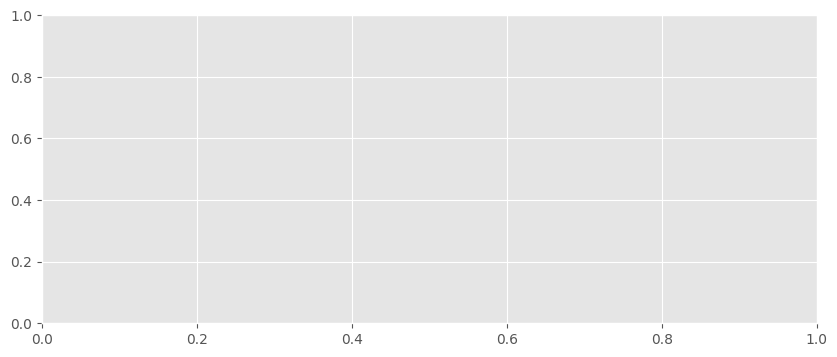

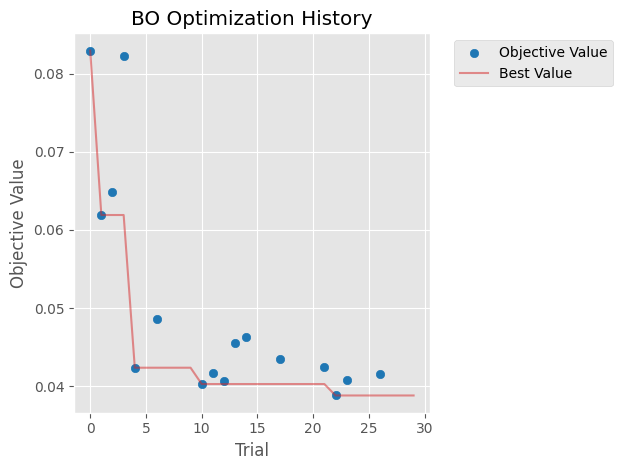

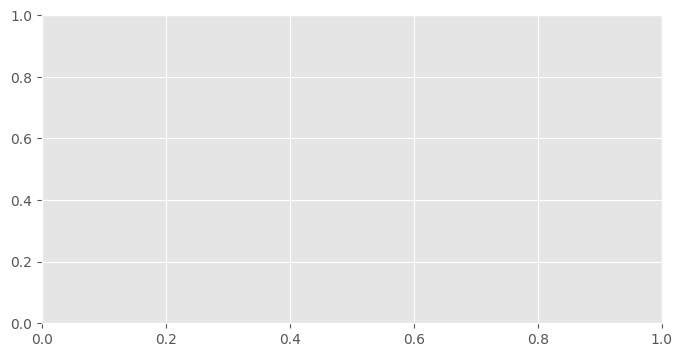

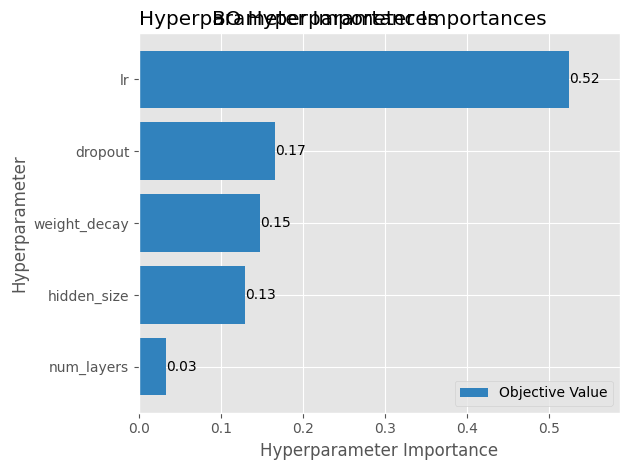

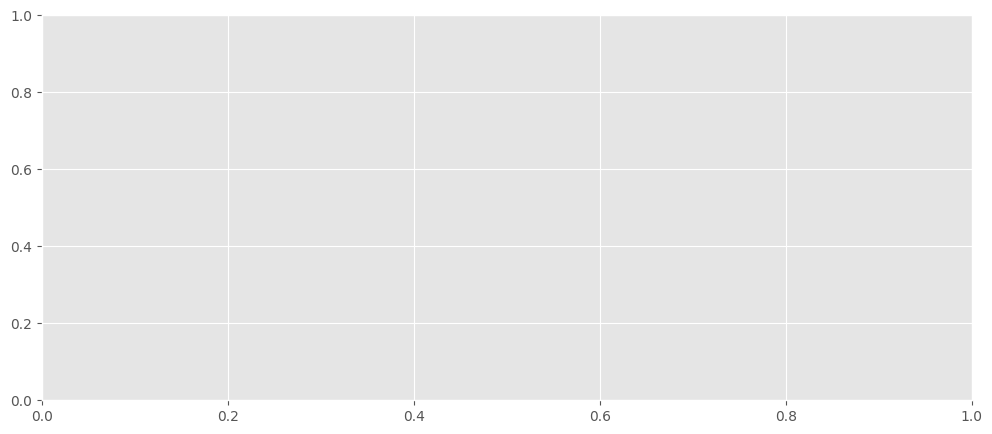

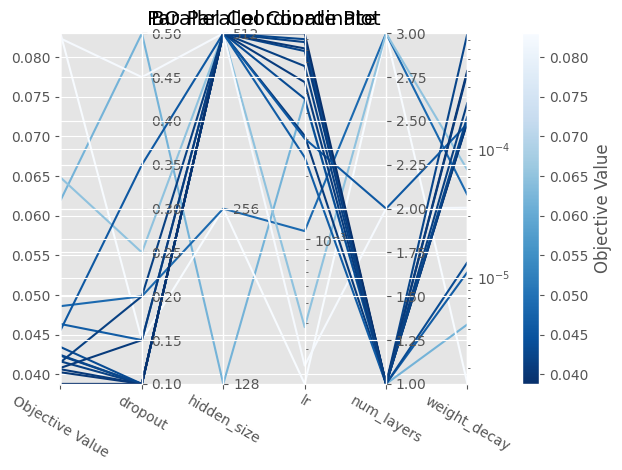

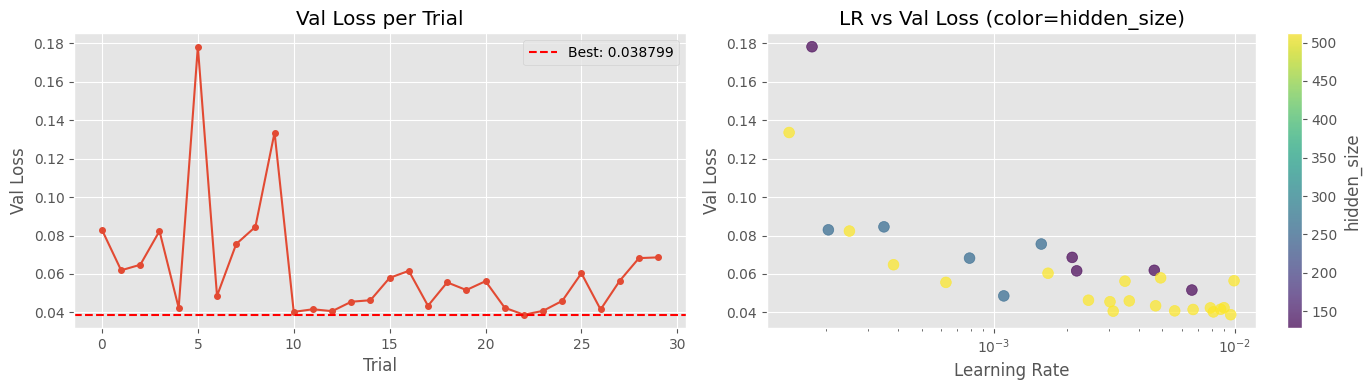

시각화 4종 저장 완료 → bo_results/


In [23]:
# BO 결과 시각화 (3종) — bo_results 폴더에 저장
import optuna.visualization.matplotlib as ovm

_ts2 = datetime.now().strftime('%Y%m%d_%H%M%S')

# 그래프 1: Optimization History
fig, ax = plt.subplots(figsize=(10, 4))
ovm.plot_optimization_history(study)
plt.title('BO Optimization History')
plt.tight_layout()
plt.savefig(os.path.join(BO_RESULT_DIR, f'bo_history_{_ts2}.png'), dpi=150)
plt.show()

# 그래프 2: Param Importances
fig, ax = plt.subplots(figsize=(8, 4))
ovm.plot_param_importances(study)
plt.title('BO Hyperparameter Importances')
plt.tight_layout()
plt.savefig(os.path.join(BO_RESULT_DIR, f'bo_param_importance_{_ts2}.png'), dpi=150)
plt.show()

# 그래프 3: Parallel Coordinate
fig, ax = plt.subplots(figsize=(12, 5))
ovm.plot_parallel_coordinate(study)
plt.title('BO Parallel Coordinate')
plt.tight_layout()
plt.savefig(os.path.join(BO_RESULT_DIR, f'bo_parallel_{_ts2}.png'), dpi=150)
plt.show()

# 그래프 4: Val Loss 분포 (완료된 trial만)
_df_c = pd.DataFrame(bo_trial_records)
_df_c = _df_c[_df_c['state']=='COMPLETE'].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(_df_c['trial'], _df_c['val_loss'], 'o-', markersize=4)
axes[0].axhline(study.best_value, color='red', linestyle='--', label=f'Best: {study.best_value:.6f}')
axes[0].set_xlabel('Trial'); axes[0].set_ylabel('Val Loss')
axes[0].set_title('Val Loss per Trial'); axes[0].legend(); axes[0].grid(True)

axes[1].scatter(_df_c['lr'], _df_c['val_loss'],
                c=_df_c['hidden_size'], cmap='viridis', alpha=0.7, s=60)
axes[1].set_xscale('log'); axes[1].set_xlabel('Learning Rate')
axes[1].set_ylabel('Val Loss'); axes[1].set_title('LR vs Val Loss (color=hidden_size)')
axes[1].grid(True)
plt.colorbar(axes[1].collections[0], ax=axes[1], label='hidden_size')
plt.tight_layout()
plt.savefig(os.path.join(BO_RESULT_DIR, f'bo_custom_{_ts2}.png'), dpi=150)
plt.show()

print(f'시각화 4종 저장 완료 → {BO_RESULT_DIR}/')

## 6. 학습 설정

In [24]:
# ⚙️ 학습 하이퍼파라미터 (BO 최적값 자동 적용)
EPOCHS   = 50
PATIENCE = 7

try:
    _lr, _wd = LR_BEST, WD_BEST
    print(f'✅ BO lr={_lr:.6f}, weight_decay={_wd:.8f}')
except NameError:
    _lr, _wd = 1e-3, 1e-5
    print(f'⚠️  기본값 lr={_lr}, weight_decay={_wd}')

criterion  = nn.MSELoss()
optimizer  = torch.optim.Adam(model.parameters(), lr=_lr, weight_decay=_wd)
scheduler  = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)
scaler_amp = torch.cuda.amp.GradScaler()  # AMP

def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    for x_num, x_cat, y in loader:
        x_num, x_cat, y = x_num.to(DEVICE), x_cat.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            pred = model(x_num, x_cat)
            loss = criterion(pred, y)
        scaler_amp.scale(loss).backward()
        scaler_amp.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler_amp.step(optimizer)
        scaler_amp.update()
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0
    for x_num, x_cat, y in loader:
        x_num, x_cat, y = x_num.to(DEVICE), x_cat.to(DEVICE), y.to(DEVICE)
        with torch.cuda.amp.autocast():
            pred = model(x_num, x_cat)
            loss = criterion(pred, y)
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset)

print('학습 설정 완료')

✅ BO lr=0.009599, weight_decay=0.00040915
학습 설정 완료


## 7. 학습 실행

In [25]:
train_losses, val_losses = [], []
best_val_loss = float('inf')
patience_cnt  = 0
SAVE_PATH     = 'best_lstm_model.pt'

for epoch in range(1, EPOCHS + 1):
    tr_loss = train_one_epoch(model, train_loader)
    vl_loss = evaluate(model, val_loader)

    train_losses.append(tr_loss)
    val_losses.append(vl_loss)
    scheduler.step(vl_loss)

    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        torch.save(model.state_dict(), SAVE_PATH)
        patience_cnt = 0
        marker = ' ✅ saved'
    else:
        patience_cnt += 1
        marker = f' (patience {patience_cnt}/{PATIENCE})'

    print(f'Epoch {epoch:3d}/{EPOCHS} | Train Loss: {tr_loss:.6f} | Val Loss: {vl_loss:.6f}{marker}')

    if patience_cnt >= PATIENCE:
        print(f'\n Early Stopping at epoch {epoch}')
        break

print(f'\n최적 Val Loss: {best_val_loss:.6f}')

Epoch   1/50 | Train Loss: 0.513021 | Val Loss: 0.086346 ✅ saved
Epoch   2/50 | Train Loss: 0.187245 | Val Loss: 0.105265 (patience 1/7)
Epoch   3/50 | Train Loss: 0.270789 | Val Loss: 1.206731 (patience 2/7)
Epoch   4/50 | Train Loss: 0.983106 | Val Loss: 1.192757 (patience 3/7)
Epoch   5/50 | Train Loss: 0.967003 | Val Loss: 1.208161 (patience 4/7)
Epoch   6/50 | Train Loss: 0.966973 | Val Loss: 1.209137 (patience 5/7)
Epoch   7/50 | Train Loss: 0.966975 | Val Loss: 1.201587 (patience 6/7)
Epoch   8/50 | Train Loss: 0.966977 | Val Loss: 1.192235 (patience 7/7)

 Early Stopping at epoch 8

최적 Val Loss: 0.086346


## 8. 학습 곡선 시각화

In [2]:
plt.figure(figsize=(10, 4))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses,   label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('learning_curve.png', dpi=150)
plt.show()

NameError: name 'plt' is not defined

## 9. 테스트 평가

In [27]:
# 최적 모델 로드
model.load_state_dict(torch.load(SAVE_PATH, map_location=DEVICE))
model.eval()

all_preds, all_trues = [], []

with torch.no_grad():
    for x_num, x_cat, y in test_loader:
        x_num, x_cat = x_num.to(DEVICE), x_cat.to(DEVICE)
        pred = model(x_num, x_cat).cpu().numpy()
        all_preds.append(pred)
        all_trues.append(y.numpy())

preds = np.concatenate(all_preds, axis=0)  # (N, 3)
trues = np.concatenate(all_trues, axis=0)  # (N, 3)

# 역변환 (스케일드 → 원본 단위)
def inverse_vol(x_scaled):
    x_log = scalers['VOL'].inverse_transform(x_scaled.reshape(-1,1)).flatten()
    return np.expm1(x_log)

def inverse_spd(x_scaled):
    return scalers['SPD'].inverse_transform(x_scaled.reshape(-1,1)).flatten()

def inverse_occ(x_scaled):
    x_log = scalers['OCC'].inverse_transform(x_scaled.reshape(-1,1)).flatten()
    return np.expm1(x_log)

TARGET_NAMES = ['VOL', 'SPD', 'OCC']
inv_funcs    = [inverse_vol, inverse_spd, inverse_occ]

print('=' * 60)
print(f'{'Target':<8} {'RMSE':>10} {'MAE':>10} {'R²':>8}')
print('-' * 60)

for i, (name, inv_fn) in enumerate(zip(TARGET_NAMES, inv_funcs)):
    p = inv_fn(preds[:, i])
    t = inv_fn(trues[:, i])
    rmse = np.sqrt(mean_squared_error(t, p))
    mae  = mean_absolute_error(t, p)
    r2   = r2_score(t, p)
    print(f'{name:<8} {rmse:>10.4f} {mae:>10.4f} {r2:>8.4f}')

print('=' * 60)

Target         RMSE        MAE       R²
------------------------------------------------------------
VOL         35.4294    26.5507   0.8733
SPD          5.4100     4.0236   0.9028
OCC          3.6824     2.1954   0.8774


## 10. 예측 결과 시각화

In [1]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
PLOT_N = 500  # 시각화할 샘플 수

for i, (name, inv_fn) in enumerate(zip(TARGET_NAMES, inv_funcs)):
    p = inv_fn(preds[:PLOT_N, i])
    t = inv_fn(trues[:PLOT_N, i])
    axes[i].plot(t, label='Actual',    linewidth=1.0, alpha=0.8)
    axes[i].plot(p, label='Predicted', linewidth=1.0, alpha=0.8, linestyle='--')
    axes[i].set_title(f'{name} 예측 vs 실제')
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.savefig('prediction_result.png', dpi=150)
plt.show()

NameError: name 'plt' is not defined

## 11. 모델 저장 (추론용)

In [29]:
import pickle

# 스케일러 저장
with open('scalers.pkl', 'wb') as f:
    pickle.dump(scalers, f)

# 인코더 저장
with open('encoders.pkl', 'wb') as f:
    pickle.dump({'route_enc': route_enc, 'link_enc': link_enc}, f)

# 모델 설정 저장
model_config = {
    'num_numeric_features': len(NUM_FEATURES),
    'num_routes':    NUM_ROUTES,
    'route_emb_dim': ROUTE_EMB_DIM,
    'num_links':     NUM_LINKS,
    'link_emb_dim':  LINK_EMB_DIM,
    'hidden_size':   512,
    'num_layers':    3,
    'dropout':       0.3,
    'output_size':   3,
    'pred_steps':    PRED_STEPS,
    'seq_len':       SEQ_LEN,
    'num_features':  NUM_FEATURES,
}
with open('model_config.pkl', 'wb') as f:
    pickle.dump(model_config, f)

print('저장 완료: best_lstm_model.pt / scalers.pkl / encoders.pkl / model_config.pkl')

저장 완료: best_lstm_model.pt / scalers.pkl / encoders.pkl / model_config.pkl
